In [1]:
# Importação das bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Ambiente de análise de dados configurado!")

Ambiente de análise de dados configurado!


# Análise Exploratória de Dados de Vendas

## 1. Introdução

Este projeto tem como objetivo realizar uma análise exploratória
de dados de vendas de uma empresa varejista fictícia.

A análise busca identificar padrões de vendas, produtos com melhor
desempenho, faturamento por região e comportamento das vendas
ao longo do tempo.

## 2. Objetivos

- Analisar o faturamento total.
- Identificar os produtos mais vendidos.
- Comparar o desempenho das categorias.
- Avaliar as vendas por região.
- Identificar tendências temporais.

## 3. Ferramentas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## 4. Base de dados

Base de dados fictícia, criada em Python para fins de estudos.

In [2]:
# Criando uma base de dados fictícia de vendas

import pandas as pd
import numpy as np
from pathlib import Path

# Garantindo resultados reproduzíveis
np.random.seed(42)

# Quantidade de registros
total_registros = 500

# Produtos disponíveis
produtos = {
    "Notebook": ("Eletrônicos", 3500),
    "Smartphone": ("Eletrônicos", 2200),
    "Monitor": ("Eletrônicos", 1200),
    "Cadeira": ("Móveis", 850),
    "Mesa": ("Móveis", 1100),
    "Estante": ("Móveis", 650),
    "Cafeteira": ("Eletrodomésticos", 280),
    "Liquidificador": ("Eletrodomésticos", 190),
    "Ventilador": ("Eletrodomésticos", 230),
}

# Sorteando os produtos
lista_produtos = np.random.choice(
    list(produtos.keys()),
    total_registros
)

# Criando as informações das vendas
dados = []

for i, produto in enumerate(lista_produtos):

    categoria, preco = produtos[produto]

    quantidade = np.random.randint(1, 6)
    desconto = np.random.choice([0, 0.05, 0.10, 0.15])

    dados.append({
        "id_venda": i + 1,
        "data_venda": np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31")
        ),
        "produto": produto,
        "categoria": categoria,
        "regiao": np.random.choice([
            "Sudeste", "Sul", "Nordeste",
            "Centro-Oeste", "Norte"
        ]),
        "quantidade": quantidade,
        "preco_unitario": preco,
        "desconto": desconto
    })

# Transformando os dados em DataFrame
df_vendas = pd.DataFrame(dados)

# Calculando o faturamento líquido
df_vendas["faturamento"] = (
    df_vendas["quantidade"]
    * df_vendas["preco_unitario"]
    * (1 - df_vendas["desconto"])
)

# Organizando as datas
df_vendas["data_venda"] = pd.to_datetime(
    df_vendas["data_venda"]
)

# Salvando o arquivo CSV
caminho = Path(
    "01-analise-exploratoria-vendas/dados/vendas.csv"
)

caminho.parent.mkdir(parents=True, exist_ok=True)

df_vendas.to_csv(
    caminho,
    index=False,
    encoding="utf-8-sig"
)

print("Base de dados criada com sucesso!")

Base de dados criada com sucesso!


In [3]:
# Visualizando os primeiros registros

df_vendas.head()

,id_venda,data_venda,produto,categoria,regiao,quantidade,preco_unitario,desconto,faturamento
0,1,2025-10-02,Cafeteira,Eletrodomésticos,Norte,4,280,0.10,1008.0
1,2,2025-06-16,Cadeira,Móveis,Nordeste,4,850,0.05,3230.0
2,3,2025-01-19,Liquidificador,Eletrodomésticos,Nordeste,2,190,0.05,361.0
3,4,2025-08-30,Mesa,Móveis,Centro-Oeste,5,1100,0.00,5500.0
4,5,2025-11-13,Cafeteira,Eletrodomésticos,Sudeste,2,280,0.15,476.0


In [4]:
# Verificando o tamanho da base

print("Quantidade de registros:", df_vendas.shape[0])
print("Quantidade de colunas:", df_vendas.shape[1])

Quantidade de registros: 500
Quantidade de colunas: 9


## 5. Conhecendo a Base de Dados

Nesta etapa será realizada uma análise inicial da estrutura
da base de vendas, identificando tipos de dados, dimensões
e características das variáveis.

In [5]:
# Visualizando as informações gerais da base

df_vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_venda        500 non-null    int64         
 1   data_venda      500 non-null    datetime64[us]
 2   produto         500 non-null    str           
 3   categoria       500 non-null    str           
 4   regiao          500 non-null    str           
 5   quantidade      500 non-null    int64         
 6   preco_unitario  500 non-null    int64         
 7   desconto        500 non-null    float64       
 8   faturamento     500 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(3), str(3)
memory usage: 35.3 KB


In [6]:
# Estatísticas descritivas das variáveis numéricas

df_vendas.describe()

,id_venda,data_venda,quantidade,preco_unitario,desconto,faturamento
count,500.000000,500,500.000000,500.000000,500.000000,500.000000
mean,250.500000,2025-06-26 05:28:19.200000,3.078000,1177.840000,0.070500,3423.780000
min,1.000000,2025-01-01 00:00:00,1.000000,190.000000,0.000000,161.500000
25%,125.750000,2025-03-22 00:00:00,2.000000,280.000000,0.000000,805.125000
50%,250.500000,2025-06-22 00:00:00,3.000000,850.000000,0.050000,2040.000000
75%,375.250000,2025-10-03 06:00:00,4.000000,1200.000000,0.100000,4320.000000
max,500.000000,2025-12-31 00:00:00,5.000000,3500.000000,0.150000,17500.000000
std,144.481833,NaN,1.419841,1078.691655,0.055686,3808.648358


In [7]:
# Verificando valores ausentes

df_vendas.isnull().sum()

id_venda          0
data_venda        0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
desconto          0
faturamento       0
dtype: int64

In [8]:
# Verificando registros duplicados

print("Registros duplicados:", df_vendas.duplicated().sum())

Registros duplicados: 0


## 6. Análise Exploratória das Vendas

Nesta etapa serão investigadas as características comerciais
da base, considerando produtos, categorias, regiões e
distribuição temporal das vendas.

In [9]:
# Quantidade de vendas por produto

vendas_produto = (
    df_vendas["produto"]
    .value_counts()
)

vendas_produto

produto
Notebook          68
Monitor           63
Cafeteira         62
Mesa              57
Cadeira           56
Liquidificador    53
Ventilador        53
Estante           44
Smartphone        44
Name: count, dtype: int64

In [10]:
# Faturamento total por categoria

faturamento_categoria = (
    df_vendas.groupby("categoria")["faturamento"]
    .sum()
    .sort_values(ascending=False)
)

faturamento_categoria

categoria
Eletrônicos         1191535.0
Móveis               410427.5
Eletrodomésticos     109927.5
Name: faturamento, dtype: float64

In [11]:
# Quantidade de vendas por região

vendas_regiao = (
    df_vendas["regiao"]
    .value_counts()
)

vendas_regiao

regiao
Sul             115
Sudeste         109
Nordeste         95
Norte            91
Centro-Oeste     90
Name: count, dtype: int64

In [12]:
# Total de unidades vendidas por produto

unidades_produto = (
    df_vendas.groupby("produto")["quantidade"]
    .sum()
    .sort_values(ascending=False)
)

unidades_produto

produto
Notebook          216
Mesa              189
Cafeteira         180
Monitor           177
Liquidificador    168
Cadeira           167
Ventilador        158
Smartphone        146
Estante           138
Name: quantidade, dtype: int64

In [13]:
# Faturamento total por região

faturamento_regiao = (
    df_vendas.groupby("regiao")["faturamento"]
    .sum()
    .sort_values(ascending=False)
)

faturamento_regiao

regiao
Sul             379247.0
Sudeste         374397.5
Norte           349058.5
Nordeste        322887.5
Centro-Oeste    286299.5
Name: faturamento, dtype: float64

In [14]:
# Criando uma coluna com o mês da venda

df_vendas["mes"] = (
    df_vendas["data_venda"].dt.month
)

# Somando o faturamento mensal

faturamento_mensal = (
    df_vendas.groupby("mes")["faturamento"]
    .sum()
)

faturamento_mensal

mes
1     230868.5
2     155979.5
3     126588.5
4     156135.0
5      81233.5
6     142585.0
7     129581.5
8     153790.5
9     131640.0
10    157123.5
11    126968.0
12    119396.5
Name: faturamento, dtype: float64

## 7. Principais descobertas iniciais

A análise preliminar identificou:

- Notebook foi o produto com maior frequência de vendas.
- Eletrônicos apresentou o maior faturamento entre as categorias.
- A região Sul apresentou a maior quantidade de registros de vendas.

Os resultados indicam uma concentração relevante do faturamento
na categoria de Eletrônicos.

As próximas análises investigarão a quantidade de unidades
vendidas, o faturamento regional e o comportamento mensal das vendas.

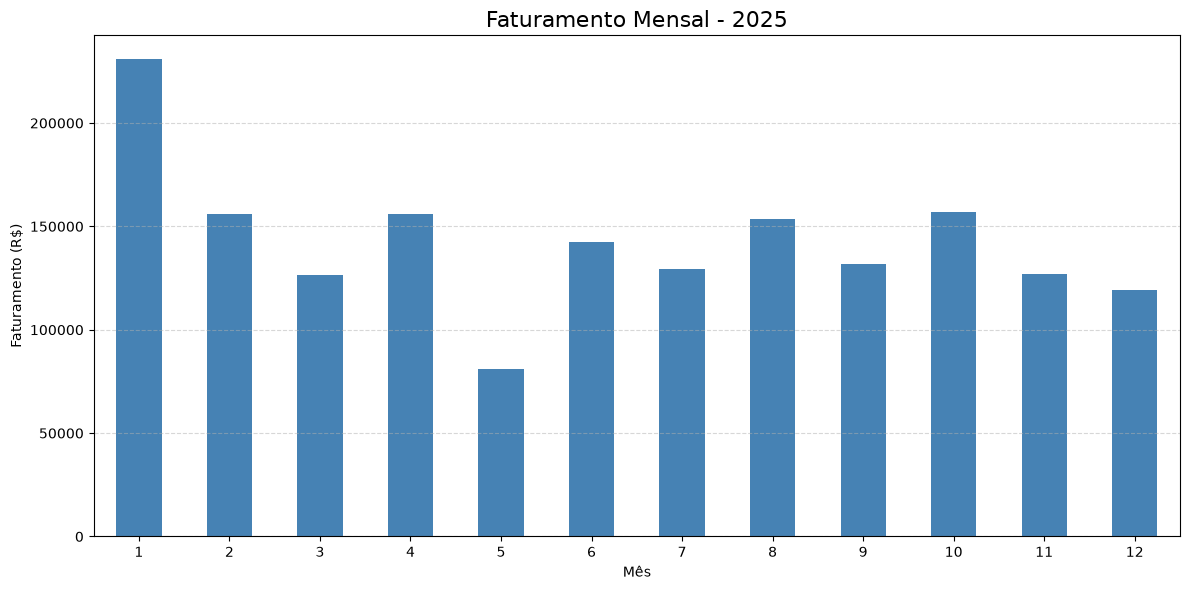

In [15]:
# Gráfico de faturamento mensal

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

faturamento_mensal.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Faturamento Mensal - 2025", fontsize=16)
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [16]:
# Substituindo números pelos nomes dos meses

nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

faturamento_mensal.index = faturamento_mensal.index.map(nomes_meses)

faturamento_mensal

mes
Janeiro      230868.5
Fevereiro    155979.5
Março        126588.5
Abril        156135.0
Maio          81233.5
Junho        142585.0
Julho        129581.5
Agosto       153790.5
Setembro     131640.0
Outubro      157123.5
Novembro     126968.0
Dezembro     119396.5
Name: faturamento, dtype: float64

In [17]:
# Comparando faturamento de abril e maio

abril = faturamento_mensal["Abril"]
maio = faturamento_mensal["Maio"]

variacao = ((maio - abril) / abril) * 100

print(f"Faturamento de abril: R$ {abril:,.2f}")
print(f"Faturamento de maio: R$ {maio:,.2f}")
print(f"Variação percentual: {variacao:.2f}%")

Faturamento de abril: R$ 156,135.00
Faturamento de maio: R$ 81,233.50
Variação percentual: -47.97%


In [18]:
# Comparando faturamento por produto em abril e maio

comparacao_meses = (
    df_vendas[df_vendas["mes"].isin([4, 5])]
    .groupby(["mes", "produto"])["faturamento"]
    .sum()
    .unstack()
)

comparacao_meses.index = ["Abril", "Maio"]

comparacao_meses

produto,Cadeira,Cafeteira,Estante,Liquidificador,Mesa,Monitor,Notebook,Smartphone,Ventilador
Abril,11262.5,7966.0,4712.5,874.0,12375.0,11280.0,75600.0,30800.0,1265.0
Maio,8160.0,4242.0,NaN,921.5,8250.0,17700.0,35350.0,3850.0,2760.0


In [19]:
# Tratando produtos sem registros no mês

comparacao_meses = comparacao_meses.fillna(0)

# Calculando a variação percentual por produto

variacao_produtos = (
    (comparacao_meses.loc["Maio"] -
     comparacao_meses.loc["Abril"]) /
    comparacao_meses.loc["Abril"]
) * 100

variacao_produtos.sort_values()

produto
Estante          -100.000000
Smartphone        -87.500000
Notebook          -53.240741
Cafeteira         -46.748682
Mesa              -33.333333
Cadeira           -27.547170
Liquidificador      5.434783
Monitor            56.914894
Ventilador        118.181818
dtype: float64

In [20]:
# Comparando quantidade vendida em abril e maio

quantidade_meses = (
    df_vendas[df_vendas["mes"].isin([4, 5])]
    .groupby(["mes", "produto"])["quantidade"]
    .sum()
    .unstack()
)

quantidade_meses.index = ["Abril", "Maio"]

quantidade_meses[["Notebook", "Smartphone"]]

produto,Notebook,Smartphone
Abril,23.0,15.0
Maio,11.0,2.0


In [21]:
# Comparando preço unitário médio

preco_medio = (
    df_vendas[df_vendas["mes"].isin([4, 5])]
    .groupby(["mes", "produto"])["preco_unitario"]
    .mean()
    .unstack()
)

preco_medio.index = ["Abril", "Maio"]

preco_medio[["Notebook", "Smartphone"]]

produto,Notebook,Smartphone
Abril,3500.0,2200.0
Maio,3500.0,2200.0


In [22]:
# Comparando descontos médios por produto

descontos_meses = (
    df_vendas[df_vendas["mes"].isin([4, 5])]
    .groupby(["mes", "produto"])["desconto"]
    .mean()
    .unstack()
)

descontos_meses.index = ["Abril", "Maio"]

descontos_meses[["Notebook", "Smartphone"]]

produto,Notebook,Smartphone
Abril,0.056250,0.075
Maio,0.066667,0.125


In [23]:
# Consolidando indicadores de abril e maio

resumo_produtos = pd.DataFrame({
    "Unidades_Abril": quantidade_meses.loc["Abril"],
    "Unidades_Maio": quantidade_meses.loc["Maio"],
    "Preco_Abril": preco_medio.loc["Abril"],
    "Preco_Maio": preco_medio.loc["Maio"],
    "Desconto_Abril": descontos_meses.loc["Abril"],
    "Desconto_Maio": descontos_meses.loc["Maio"]
})

resumo_produtos.loc[["Notebook", "Smartphone"]]

,Unidades_Abril,Unidades_Maio,Preco_Abril,Preco_Maio,Desconto_Abril,Desconto_Maio
produto,,,,,,
Notebook,23.0,11.0,3500.0,3500.0,0.05625,0.066667
Smartphone,15.0,2.0,2200.0,2200.0,0.07500,0.125000


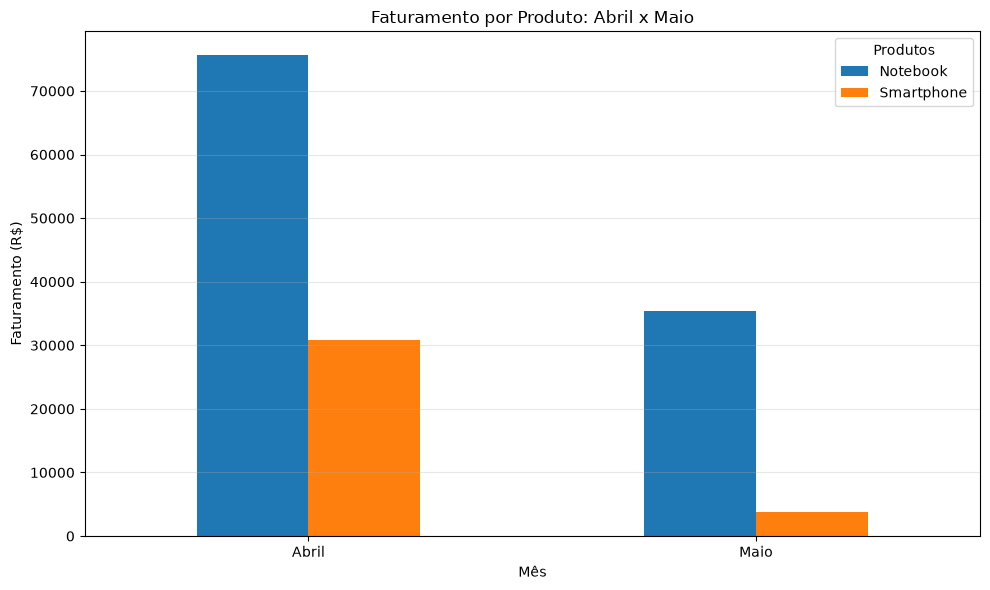

In [24]:
# Comparação do faturamento por produto

faturamento_comparativo = (
    df_vendas[df_vendas["mes"].isin([4, 5])]
    .groupby(["mes", "produto"])["faturamento"]
    .sum()
    .unstack()
)

faturamento_comparativo.index = ["Abril", "Maio"]

faturamento_comparativo[
    ["Notebook", "Smartphone"]
].plot(
    kind="bar",
    figsize=(10, 6),
    title="Faturamento por Produto: Abril x Maio",
    xlabel="Mês",
    ylabel="Faturamento (R$)",
    rot=0
)

plt.legend(title="Produtos")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

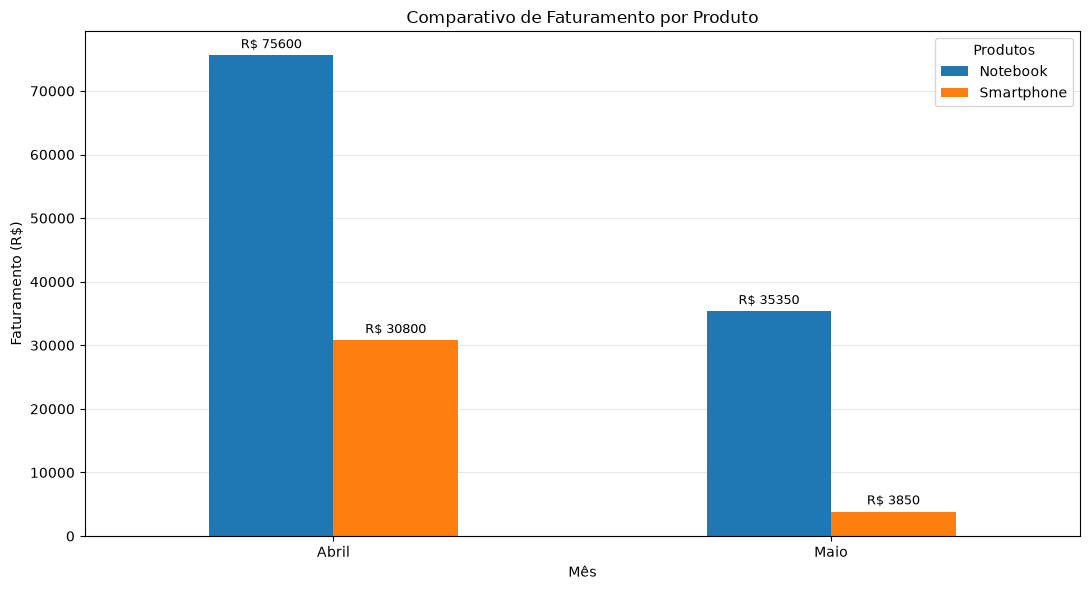

In [25]:
# Gráfico comparativo de faturamento

ax = faturamento_comparativo[
    ["Notebook", "Smartphone"]
].plot(
    kind="bar",
    figsize=(11, 6),
    title="Comparativo de Faturamento por Produto",
    xlabel="Mês",
    ylabel="Faturamento (R$)",
    rot=0
)

# Adicionando os valores sobre as barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="R$ %.0f",
        padding=3,
        fontsize=9
    )

# Ajustes visuais
ax.legend(title="Produtos")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

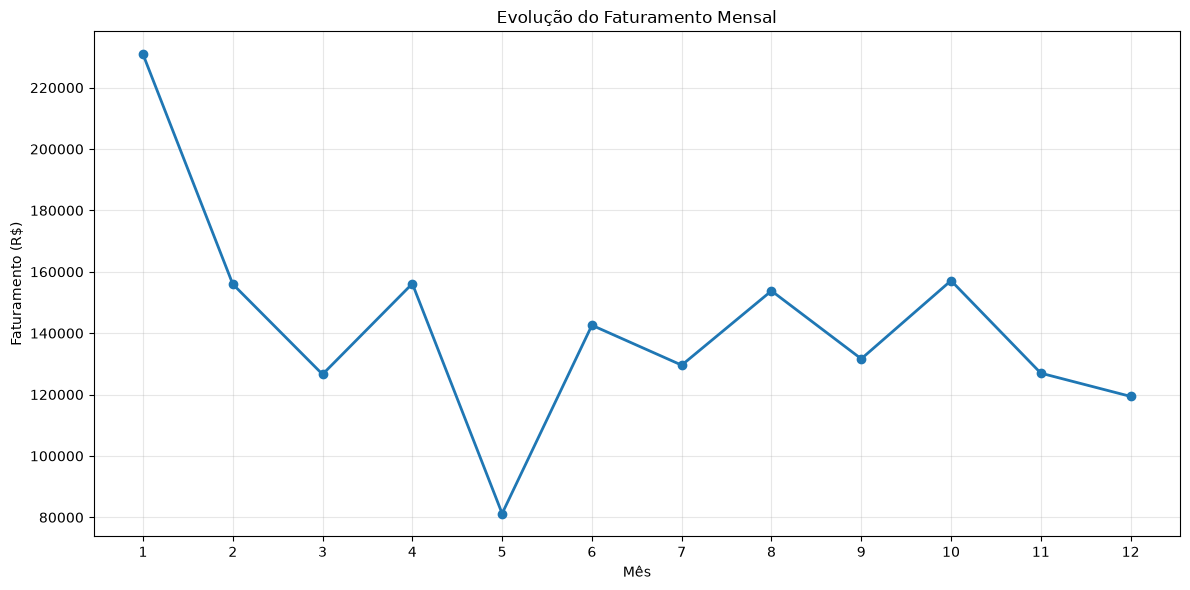

In [26]:
# Evolução do faturamento mensal

faturamento_mensal = (
    df_vendas.groupby("mes")["faturamento"]
    .sum()
)

plt.figure(figsize=(12, 6))

plt.plot(
    faturamento_mensal.index,
    faturamento_mensal.values,
    marker="o",
    linewidth=2
)

plt.title("Evolução do Faturamento Mensal")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")

plt.xticks(range(1, 13))

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

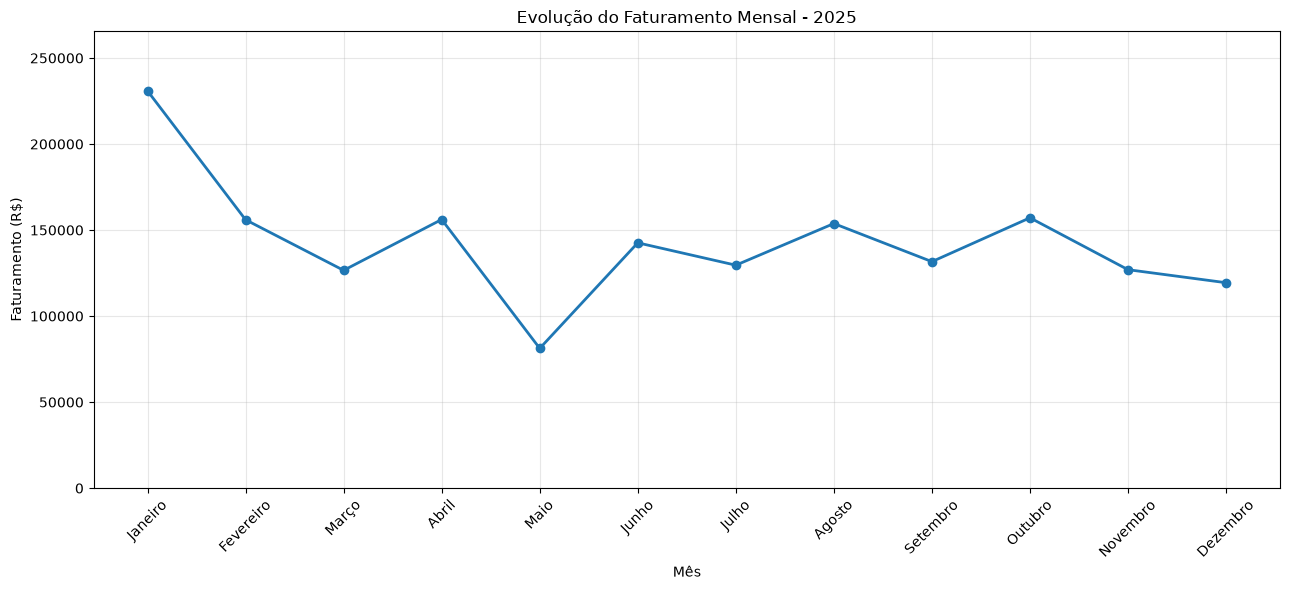

In [27]:
# Melhorando o gráfico de faturamento mensal

meses = [
    "Janeiro", "Fevereiro", "Março", "Abril",
    "Maio", "Junho", "Julho", "Agosto",
    "Setembro", "Outubro", "Novembro", "Dezembro"
]

plt.figure(figsize=(13, 6))

plt.plot(
    meses,
    faturamento_mensal.values,
    marker="o",
    linewidth=2
)

plt.title("Evolução do Faturamento Mensal - 2025")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")

plt.xticks(rotation=45)

# Evita cortar os valores extremos
plt.ylim(0, faturamento_mensal.max() * 1.15)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:
# Faturamento total por região

faturamento_regiao = (
    df_vendas.groupby("regiao")["faturamento"]
    .sum()
    .sort_values(ascending=False)
)

faturamento_regiao

regiao
Sul             379247.0
Sudeste         374397.5
Norte           349058.5
Nordeste        322887.5
Centro-Oeste    286299.5
Name: faturamento, dtype: float64

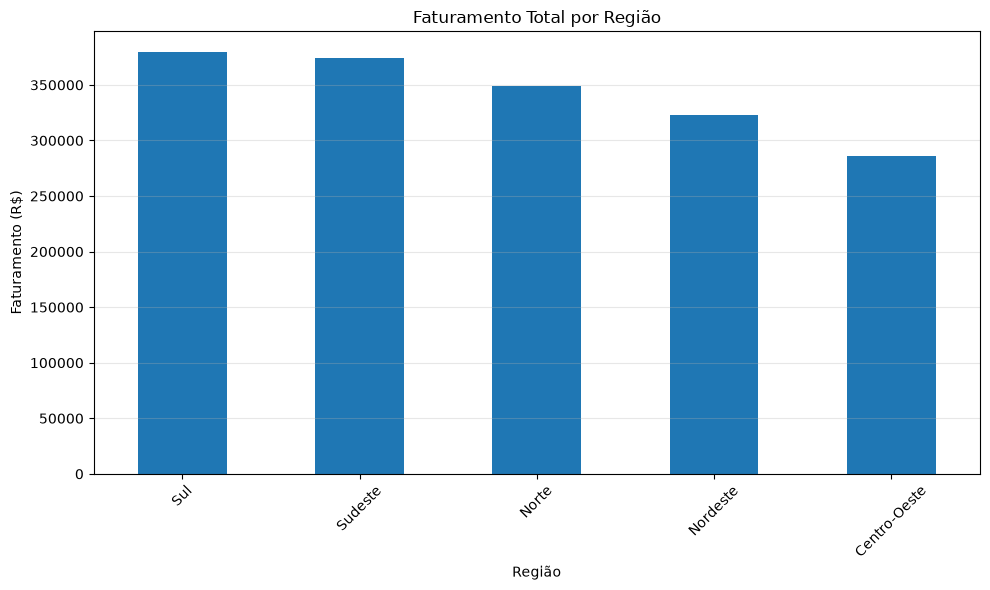

In [29]:
# Visualização do faturamento por região

plt.figure(figsize=(10, 6))

faturamento_regiao.plot(
    kind="bar",
    title="Faturamento Total por Região"
)

plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Calculando o ticket médio por região

ticket_medio_regiao = (
    df_vendas.groupby("regiao")["faturamento"]
    .mean()
    .sort_values(ascending=False)
)

ticket_medio_regiao

regiao
Norte           3835.807692
Sudeste         3434.839450
Nordeste        3398.815789
Sul             3297.800000
Centro-Oeste    3181.105556
Name: faturamento, dtype: float64